# Image Classification with PyTorch and Vision Transformers (ViT)

In this notebook we build a Vision Transformer (ViT) from scratch, following the original paper (Dosovitskiy et al., 2021, https://arxiv.org/abs/2010.11929), and use it to classify photos of pizza, steak, and sushi. The notebook has two parts:

* **Part A** (Steps 0 to 10): we build every component of the ViT ourselves and train it from scratch on our small dataset.
* **Part B** (Step 11): we take a ViT-Base model that has been pretrained on ImageNet, replace its classification head, and fine-tune it on the same data.

Comparing the two parts shows why pretraining matters so much for transformers. Both parts need internet access: Part A downloads the dataset (about 16 MB) and Part B downloads the pretrained weights (about 330 MB). A GPU is strongly recommended.

## Step 0: Install and Import Dependencies

In [1]:
# Run this if you're in Colab (or anywhere torchinfo is not installed)
# !pip install -q torchinfo

In [2]:
import torch
from torch import nn
from torchinfo import summary

## Step 1: Get the Data

The data will be downloaded and saved to the `./data` directory.

In [3]:
import requests
from pathlib import Path
import os
from zipfile import ZipFile

# Define the URL for the zip file
url = "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip"

# Define the path to the data directory
data_path = Path("data")

# Define the path to the image directory
image_path = data_path / "pizza_steak_sushi"

# Check if the image directory already exists
if image_path.is_dir():
    print(f"{image_path} directory exists, skipping the download.")
else:
    print(f"Did not find {image_path} directory, creating one and downloading the data...")
    image_path.mkdir(parents=True, exist_ok=True)

    # Send a GET request to download the file
    response = requests.get(url)

    # Write the downloaded content to a zip file
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        f.write(response.content)

    # Extract the contents of the zip file to the image directory
    with ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zipref:
        zipref.extractall(image_path)

    # Remove the downloaded zip file
    os.remove(data_path / 'pizza_steak_sushi.zip')

for split in ["train", "test"]:
    n_images = len(list((image_path / split).glob("*/*.jpg")))
    print(f"{split}: {n_images} images")

data/pizza_steak_sushi directory exists, skipping the download.
train: 225 images
test: 75 images


## Step 2: Define Transformations

1. Resize the images using `Resize()` to 224. We choose the images size to be 224 based on the ViT Paper

2. Convert to Tensor using `ToTensor()`

In [4]:
from torchvision.transforms import Resize, Compose, ToTensor

# Define the train_transform using Compose
train_transform = Compose([
    Resize((224, 224)),
    ToTensor()
])

# Define the test_transform using Compose
test_transform = Compose([
    Resize((224, 224)),
    ToTensor()
])

## Step 3: Create Dataset and DataLoader

We can use PyTorch’s `ImageFolder` dataset class to create our datasets. The training set has only 225 images (78 pizza, 75 steak, and 72 sushi) and the test set has 75 images (25 pizza, 19 steak, and 31 sushi).

For ImageFolder to work this is how your data folder needs to be structured.
```
data
└── pizza_steak_sushi
    ├── test
    │   ├── pizza
    │   ├── steak
    │   └── sushi
    └── train
        ├── pizza
        ├── steak
        └── sushi
```
All the `pizza` images will be in the pizza folder of train and test sub folders and so on for all the classes that you have.

There are two useful methods that you can call on the created `training_dataset` and `test_dataset`.

- `training_dataset.classes` that gives `['pizza', 'steak', 'sushi']`
- `training_dataset.class_to_idx` that gives `{'pizza': 0, 'steak': 1, 'sushi': 2}`

In [5]:
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

BATCH_SIZE = 16  # ViT-Base needs about 3 GB of GPU memory to train at this batch size

# Define the data directory
data_dir = Path("data/pizza_steak_sushi")

# Create the training dataset using ImageFolder
training_dataset = ImageFolder(root=data_dir / "train", transform=train_transform)

# Create the test dataset using ImageFolder
test_dataset = ImageFolder(root=data_dir / "test", transform=test_transform)

# Create the training dataloader using DataLoader
training_dataloader = DataLoader(
    dataset=training_dataset,
    shuffle=True,
    batch_size=BATCH_SIZE,
    num_workers=2,
    drop_last=True  # Drop the last batch if it is not complete (with 225 images it would contain a single image)
)

# Create the test dataloader using DataLoader
test_dataloader = DataLoader(
    dataset=test_dataset,
    shuffle=False,
    batch_size=BATCH_SIZE,
    num_workers=2
)

We can visualize a few training dataset images and see their labels

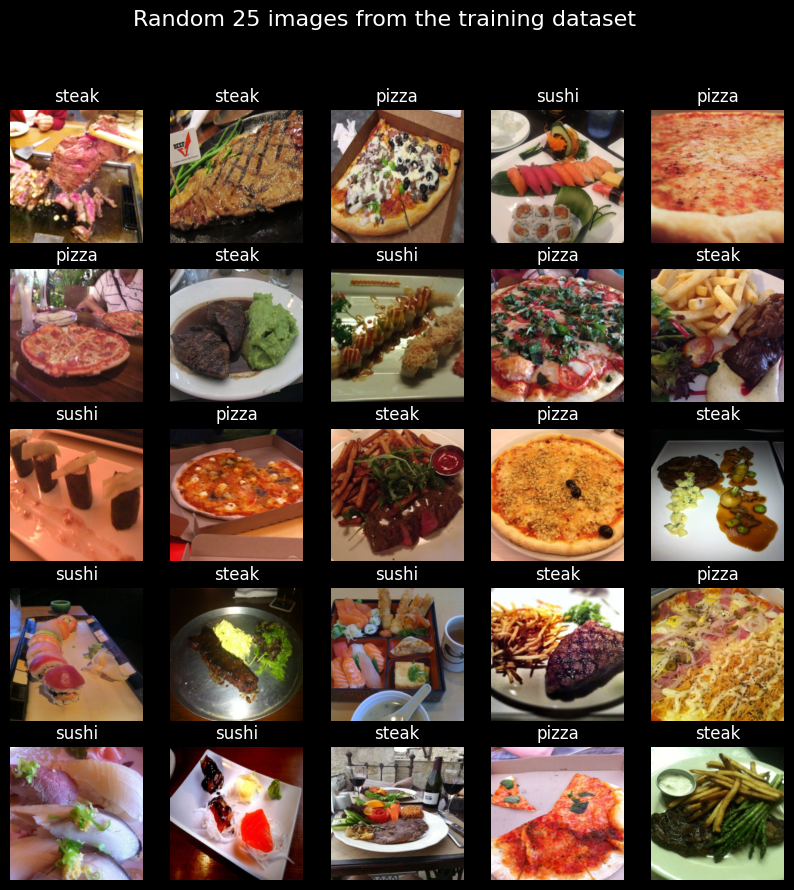

In [6]:
import matplotlib.pyplot as plt
import random

num_rows = 5
num_cols = num_rows

# Create a figure with subplots
fig, axs = plt.subplots(num_rows, num_cols, figsize=(10, 10))

# Iterate over the subplots and display random images from the training dataset
for i in range(num_rows):
    for j in range(num_cols):
        # Choose a random index from the training dataset
        image_index = random.randrange(len(training_dataset))

        # Display the image in the subplot
        axs[i, j].imshow(training_dataset[image_index][0].permute((1, 2, 0)))

        # Set the title of the subplot as the corresponding class name
        axs[i, j].set_title(training_dataset.classes[training_dataset[image_index][1]], color="white")

        # Disable the axis for better visualization
        axs[i, j].axis(False)

# Set the super title of the figure
fig.suptitle(f"Random {num_rows * num_cols} images from the training dataset", fontsize=16, color="white")

# Set the background color of the figure as black
fig.set_facecolor(color='black')

# Display the plot
plt.show()

### Understanding Vision Transformer Architecture
Let us take some time now to understand the Vision Transformer Architecture. This is the link to the original vision transformer paper: https://arxiv.org/abs/2010.11929.

Below, you can see the architecture that is proposed in the image.

![ViT Architecture](images/Vision_Transformer_Architecture_woi9aw.png)

The Vision Transformer (ViT) is a type of Transformer architecture designed for image processing tasks. Unlike traditional Transformers that operate on sequences of word embeddings, ViT operates on sequences of image embeddings. In other words, it breaks down an input image into patches and treats them as a sequence of learnable embeddings.

At a broad level, what ViT does is, it:
1. Creates Patch Embeddings
   - Takes an input image of a given size $(H \times W \times C)$ -> (Height, Width, Channels)
   - Breaks it down into N patches of a given size: $P$ -> PATCH_SIZE
   - Converts the patches into a sequence of embedding vectors with a learned linear map $\mathbf{E} \in \mathbb{R}^{(P^2 \cdot C) \times D}$
   - Prepends a learnable classification token embedding vector to the patch embeddings
   - Adds learnable position embeddings to the patch embeddings: $\mathbf{E}_{pos} \in \mathbb{R}^{(N+1) \times D}$

2. Passes embeddings through Transformer Blocks:
   - The patch embeddings, along with the classification token, are passed through multiple Transformer blocks.
   - Each Transformer block consists of a MultiHead Self-Attention Block (MSA Block) and a Multi-Layer Perceptron Block (MLP Block).
   - Skip (residual) connections add the input of the MSA block to its output, and the input of the MLP block to its output. These skip connections help mitigate the vanishing gradient problem as more Transformer blocks are added.

3. Performs Classification:
   - The output of the Transformer blocks at the position of the classification token, which by now has gathered information from all the patches, is passed through a classification head (LayerNorm and a linear layer) to make the prediction.

We will dive into each of these steps in detail, starting with the crucial process of creating patch embeddings.

## Step 4: Create Patch Embedding Layer
For the ViT paper, we need to perform the following functions on the image before passing to the MultiHead Self Attention Transformer Layer

1. Convert the image into patches of 16 x 16 size.
2. Embed each patch into 768 dimensions. So each patch becomes a [1 x 768] Vector. There will be $N = \frac{H \times W}{P^2}$ number of patches for each image. This results in an image that is of the shape [14 x 14 x 768]
3. Flatten the image along a single vector. This will give a [196 x 768] Matrix, which is our Image Embedding Sequence.
4. Prepend the Class Token Embeddings to the above output
5. Add the Position Embeddings to the Class Token and Image Embeddings.

![vision_transformer_process_neehov.gif](images/vision_transformer_process_neehov.gif)

In [7]:
PATCH_SIZE = 16
IMAGE_WIDTH = 224
IMAGE_HEIGHT = IMAGE_WIDTH
IMAGE_CHANNELS = 3
EMBEDDING_DIMS = IMAGE_CHANNELS * PATCH_SIZE**2
NUM_OF_PATCHES = int((IMAGE_WIDTH * IMAGE_HEIGHT) / PATCH_SIZE**2)
NUM_CLASSES = len(training_dataset.classes)

#the image width and image height should be divisible by patch size. This is a check to see that.

assert IMAGE_WIDTH % PATCH_SIZE == 0 and IMAGE_HEIGHT % PATCH_SIZE ==0 , print("Image Width is not divisible by patch size")

#### Step 4.1 Converting the image into patches of 16 x 16 and creating an embedding vector for each patch of size 768.

This can be accomplished by using a Conv2D Layer with a kernel_size equal to patch_size and a stride equal to patch_size

![CNN Flatten](images/CNN_Flatten_vfq1q6.png)

In [8]:
conv_layer = nn.Conv2d(in_channels = IMAGE_CHANNELS, out_channels = EMBEDDING_DIMS, kernel_size = PATCH_SIZE, stride = PATCH_SIZE)

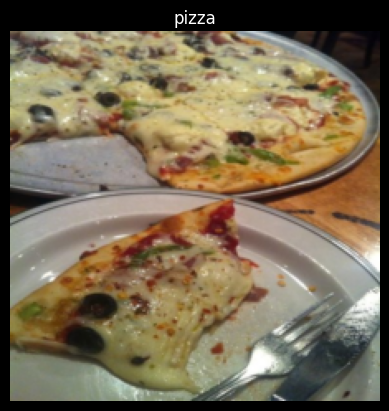

In [9]:
random_images, random_labels = next(iter(training_dataloader))
random_image = random_images[0]

# Create a new figure
fig = plt.figure(1)

# Display the random image
plt.imshow(random_image.permute((1, 2, 0)))

# Disable the axis for better visualization
plt.axis(False)

# Set the title of the image
plt.title(training_dataset.classes[random_labels[0]], color="white")

# Set the background color of the figure as black
fig.set_facecolor(color="black")

We need to change the shape to [1, 14, 14, 768] and flatten the output to [1, 196, 768]

In [10]:
# Pass the image through the convolution layer
image_through_conv = conv_layer(random_image.unsqueeze(0))
print(f'Shape of embeddings through the conv layer -> {list(image_through_conv.shape)} <- [batch_size, embedding_dims, num_of_patch_rows, num_patch_cols]')

# Permute the dimensions of image_through_conv to match the expected shape
image_through_conv = image_through_conv.permute((0, 2, 3, 1))
print(f'Shape of embeddings after the permute -> {list(image_through_conv.shape)} <- [batch_size, num_of_patch_rows, num_patch_cols, embedding_dims]')

# Create a flatten layer using nn.Flatten
flatten_layer = nn.Flatten(start_dim=1, end_dim=2)

# Pass the image_through_conv through the flatten layer
image_through_conv_and_flatten = flatten_layer(image_through_conv)

# Print the shape of the embedded image
print(f'Shape of embeddings through the flatten layer -> {list(image_through_conv_and_flatten.shape)} <- [batch_size, num_of_patches, embedding_dims]')

# Assign the embedded image to a variable
embedded_image = image_through_conv_and_flatten

Shape of embeddings through the conv layer -> [1, 768, 14, 14] <- [batch_size, embedding_dims, num_of_patch_rows, num_patch_cols]
Shape of embeddings after the permute -> [1, 14, 14, 768] <- [batch_size, num_of_patch_rows, num_patch_cols, embedding_dims]
Shape of embeddings through the flatten layer -> [1, 196, 768] <- [batch_size, num_of_patches, embedding_dims]


#### 4.2. Prepending the Class Token Embedding and Adding the Position Embeddings

The class token embedding in the Vision Transformer (ViT) serves as a pivotal element for adapting the Transformer architecture to image processing tasks. By being prepended to the sequence of image patch embeddings, the class token facilitates the aggregation of global information across the entire image through the Transformer's self-attention mechanism. As it progresses through the Transformer layers, this token encapsulates a comprehensive representation of the image, which is then utilized for classification or other downstream tasks. This strategy allows the ViT to efficiently leverage the Transformer's capabilities for variable-sized inputs and focus on relevant image parts, making it a powerful tool for end-to-end image classification and analysis.

The position embeddings are added to the class token and the sequence of patch embeddings. The position embeddings are learnable parameters that encode the spatial information of the patches in the input image.

Both are learned parameters that are shared by all images, so their first dimension is 1; in the model they are expanded (broadcast) to the batch size. As in the ViT paper, we initialize them with small random values drawn from a normal distribution (`torch.randn` scaled by 0.02).

In [11]:
class_token_embeddings = nn.Parameter(0.02 * torch.randn((1, 1, EMBEDDING_DIMS)), requires_grad=True)
print(f'Shape of class_token_embeddings --> {list(class_token_embeddings.shape)} <-- [1, 1, embedding_dims]')

embedded_image_with_class_token_embeddings = torch.cat((class_token_embeddings.expand(embedded_image.shape[0], -1, -1), embedded_image), dim = 1)
print(f'\nShape of image embeddings with class_token_embeddings --> {list(embedded_image_with_class_token_embeddings.shape)} <-- [batch_size, num_of_patches+1, embedding_dims]')

position_embeddings = nn.Parameter(0.02 * torch.randn((1, NUM_OF_PATCHES+1, EMBEDDING_DIMS)), requires_grad=True)
print(f'\nShape of position_embeddings --> {list(position_embeddings.shape)} <-- [1, num_patches+1, embedding_dims]')

final_embeddings = embedded_image_with_class_token_embeddings + position_embeddings
print(f'\nShape of final_embeddings --> {list(final_embeddings.shape)} <-- [batch_size, num_patches+1, embedding_dims]')

Shape of class_token_embeddings --> [1, 1, 768] <-- [1, 1, embedding_dims]

Shape of image embeddings with class_token_embeddings --> [1, 197, 768] <-- [batch_size, num_of_patches+1, embedding_dims]

Shape of position_embeddings --> [1, 197, 768] <-- [1, num_patches+1, embedding_dims]

Shape of final_embeddings --> [1, 197, 768] <-- [batch_size, num_patches+1, embedding_dims]


#### Put the PatchEmbeddingLayer Together

We will inherit from the PyTorch `nn.Module` to create our custom layer which takes in an image and throws out the patch embeddings which consists of the Image Embeddings, Class Token Embeddings and the Position Embeddings. The class token is stored once, with shape [1, 1, embedding_dim], and expanded to the size of the incoming batch in `forward`, so the layer works for any batch size.

In [12]:
class PatchEmbeddingLayer(nn.Module):
    def __init__(self, in_channels, patch_size, embedding_dim, img_size=224):
        super().__init__()
        self.patch_size = patch_size
        self.embedding_dim = embedding_dim
        self.in_channels = in_channels
        num_patches = (img_size // patch_size) ** 2
        self.conv_layer = nn.Conv2d(in_channels=in_channels, out_channels=embedding_dim, kernel_size=patch_size, stride=patch_size)
        self.flatten_layer = nn.Flatten(start_dim=1, end_dim=2)
        # One class token and one set of position embeddings, shared by all images in a batch
        self.class_token_embeddings = nn.Parameter(0.02 * torch.randn((1, 1, embedding_dim)), requires_grad=True)
        self.position_embeddings = nn.Parameter(0.02 * torch.randn((1, num_patches + 1, embedding_dim)), requires_grad=True)

    def forward(self, x):
        patches = self.flatten_layer(self.conv_layer(x).permute((0, 2, 3, 1)))    # [batch_size, num_patches, embedding_dim]
        class_tokens = self.class_token_embeddings.expand(x.shape[0], -1, -1)      # [batch_size, 1, embedding_dim]
        output = torch.cat((class_tokens, patches), dim=1) + self.position_embeddings
        return output

Let’s pass a batch of random images from our patch embedding layer.

In [13]:
patch_embedding_layer = PatchEmbeddingLayer(in_channels=IMAGE_CHANNELS, patch_size=PATCH_SIZE, embedding_dim=IMAGE_CHANNELS * PATCH_SIZE ** 2, img_size=IMAGE_WIDTH)

patch_embeddings = patch_embedding_layer(random_images)
patch_embeddings.shape

torch.Size([16, 197, 768])

In [14]:
summary(model=patch_embedding_layer,
        input_size=(BATCH_SIZE, 3, 224, 224), # (batch_size, input_channels, img_width, img_height)
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                       Input Shape          Output Shape         Param #              Trainable
PatchEmbeddingLayer (PatchEmbeddingLayer)     [16, 3, 224, 224]    [16, 197, 768]       152,064              True
├─Conv2d (conv_layer)                         [16, 3, 224, 224]    [16, 768, 14, 14]    590,592              True
├─Flatten (flatten_layer)                     [16, 14, 14, 768]    [16, 196, 768]       --                   --
Total params: 742,656
Trainable params: 742,656
Non-trainable params: 0
Total mult-adds (Units.GIGABYTES): 1.85
Input size (MB): 9.63
Forward/backward pass size (MB): 19.27
Params size (MB): 2.36
Estimated Total Size (MB): 31.26

## Step 5. Creating the Multi-Head Self Attention (MSA) Block.

### Understanding MSA Block
As a first step of putting together our transformer block for the Vision Transformer model, we will be creating a MultiHead Self Attention Block.

Let us take a moment to understand the MSA Block. The MSA block itself consists of a LayerNorm layer and the Multi-Head Attention Layer. The layernorm layer essentially normalizes our patch embeddings data across the embeddings dimension. The Multi-Head Attention layer takes in the input data as 3 form of learnable vectors namely query, key and value, collectively known as qkv vectors. These vectors together form the relationship between each patch of the input sequence with every other patch in the same sequence (hence the name self-attention).

So, our input shape to the MSA Block will be the shape of our patch embeddings that we made using the `PatchEmbeddingLayer -> [batch_size, sequence_length, embedding_dimensions]`. And the output from the MSA layer will be of the same shape as the input.

### MSA Block Code
Now let us begin to write code for our MSA Block. This will be short as PyTorch has a pre-built implementation of LayerNorm and the MultiHeadAttention Layer. We just have to pass the right arguments to suit our architecture (note `batch_first = True`, because our tensors have the shape [batch_size, sequence_length, embedding_dimensions]). We can find the various parameters that are required for our MSA block in this table from the original ViT Paper.

![ViT-model-variants](images/ViT-model-variants_gfeotm.png)

In [15]:
class MultiHeadSelfAttentionBlock(nn.Module):
  def __init__(self,
               embedding_dims = 768, # Hidden Size D in the ViT Paper Table 1
               num_heads = 12,  # Heads in the ViT Paper Table 1
               attn_dropout = 0.0 # Default to Zero as there is no dropout for the the MSA Block as per the ViT Paper
               ):
    super().__init__()

    self.embedding_dims = embedding_dims
    self.num_head = num_heads
    self.attn_dropout = attn_dropout

    self.layernorm = nn.LayerNorm(normalized_shape = embedding_dims)

    self.multiheadattention =  nn.MultiheadAttention(num_heads = num_heads,
                                                     embed_dim = embedding_dims,
                                                     dropout = attn_dropout,
                                                     batch_first = True,
                                                    )

  def forward(self, x):
    x = self.layernorm(x)
    output,_ = self.multiheadattention(query=x, key=x, value=x,need_weights=False)
    return output

##### Let’s test our MSA Block

In [16]:
multihead_self_attention_block = MultiHeadSelfAttentionBlock(embedding_dims = EMBEDDING_DIMS,
                                                             num_heads = 12
                                                             )
print(f'Shape of the input Patch Embeddings => {list(patch_embeddings.shape)} <= [batch_size, num_patches+1, embedding_dims ]')
print(f'Shape of the output from MSA Block => {list(multihead_self_attention_block(patch_embeddings).shape)} <= [batch_size, num_patches+1, embedding_dims ]')

Shape of the input Patch Embeddings => [16, 197, 768] <= [batch_size, num_patches+1, embedding_dims ]
Shape of the output from MSA Block => [16, 197, 768] <= [batch_size, num_patches+1, embedding_dims ]


In [17]:
summary(model=multihead_self_attention_block,
        input_size=(1, 197, 768), # (batch_size, num_patches, embedding_dimension)
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
MultiHeadSelfAttentionBlock (MultiHeadSelfAttentionBlock)    [1, 197, 768]        [1, 197, 768]        --                   True
├─LayerNorm (layernorm)                                      [1, 197, 768]        [1, 197, 768]        1,536                True
├─MultiheadAttention (multiheadattention)                    --                   [1, 197, 768]        2,362,368            True
Total params: 2,363,904
Trainable params: 2,363,904
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.61
Forward/backward pass size (MB): 1.21
Params size (MB): 0.01
Estimated Total Size (MB): 1.82

## Step 6. Creating the Multilayer Perceptron (MLP) Block

### Understanding the MLP Block

The Multilayer Perceptron (MLP) Block in the transformer is a combination of a Fully Connected Layer (also called as a Linear Layer or a Dense Layer) and a non-linear layer. In the case of ViT, the non-linear layer is a GeLU layer.

![GeLU](images/GeLU.png)

The transformer also implements a Dropout layer to reduce overfitting. So the MLP Block will look something like this:

LayerNorm → Linear → GeLU → Dropout → Linear → Dropout

According to the paper, the first Linear Layer scales the embedding dimensions to the 3072 dimensions (for the ViT-16/Base). The Dropout is set to 0.1 and the second Linear Layer scales down the dimensions back to the embedding dimensions.

### MLP Block Code

Let us now assemble our MLP Block. According to the ViT Paper, the output from the MSA Block added to the input to the MSA Block (denoted by the skip/residual connection in the model architecture figure) is passed as input to the MLP Block. All the layers are provided by the PyTorch library. We just need to assemble it.



In [18]:
class MultilayerPerceptronBlock(nn.Module):
  def __init__(self, embedding_dims, mlp_size, mlp_dropout):
    super().__init__()
    self.embedding_dims = embedding_dims
    self.mlp_size = mlp_size
    self.dropout = mlp_dropout

    self.layernorm = nn.LayerNorm(normalized_shape = embedding_dims)
    self.mlp = nn.Sequential(
        nn.Linear(in_features = embedding_dims, out_features = mlp_size),
        nn.GELU(),
        nn.Dropout(p = mlp_dropout),
        nn.Linear(in_features = mlp_size, out_features = embedding_dims),
        nn.Dropout(p = mlp_dropout)
    )

  def forward(self, x):
    return self.mlp(self.layernorm(x))

##### Let’s test our MLP Block

In [19]:
mlp_block = MultilayerPerceptronBlock(embedding_dims = EMBEDDING_DIMS,
                                           mlp_size = 3072,
                                           mlp_dropout = 0.1)

summary(model=mlp_block,
        input_size=(1, 197, 768), # (batch_size, num_patches, embedding_dimension)
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                 Input Shape          Output Shape         Param #              Trainable
MultilayerPerceptronBlock (MultilayerPerceptronBlock)   [1, 197, 768]        [1, 197, 768]        --                   True
├─LayerNorm (layernorm)                                 [1, 197, 768]        [1, 197, 768]        1,536                True
├─Sequential (mlp)                                      [1, 197, 768]        [1, 197, 768]        --                   True
│    └─Linear (0)                                       [1, 197, 768]        [1, 197, 3072]       2,362,368            True
│    └─GELU (1)                                         [1, 197, 3072]       [1, 197, 3072]       --                   --
│    └─Dropout (2)                                      [1, 197, 3072]       [1, 197, 3072]       --                   --
│    └─Linear (3)                                       [1, 197, 3072]       [1, 197, 768]        2,360,064            True
│    └─

## Step 7. Putting together the Transformer Block

In [20]:
class TransformerBlock(nn.Module):
  def __init__(self, embedding_dims = 768,
               mlp_dropout=0.1,
               attn_dropout=0.0,
               mlp_size = 3072,
               num_heads = 12,
               ):
    super().__init__()

    self.msa_block = MultiHeadSelfAttentionBlock(embedding_dims = embedding_dims,
                                                 num_heads = num_heads,
                                                 attn_dropout = attn_dropout)

    self.mlp_block = MultilayerPerceptronBlock(embedding_dims = embedding_dims,
                                                    mlp_size = mlp_size,
                                                    mlp_dropout = mlp_dropout,
                                                    )

  def forward(self,x):
    x = self.msa_block(x) + x
    x = self.mlp_block(x) + x

    return x

### Testing the Transformer Block

In [21]:
transformer_block = TransformerBlock(embedding_dims = EMBEDDING_DIMS,
                                     mlp_dropout = 0.1,
                                     attn_dropout=0.0,
                                     mlp_size = 3072,
                                     num_heads = 12)

print(f'Shape of the input Patch Embeddings => {list(patch_embeddings.shape)} <= [batch_size, num_patches+1, embedding_dims ]')
print(f'Shape of the output from Transformer Block => {list(transformer_block(patch_embeddings).shape)} <= [batch_size, num_patches+1, embedding_dims ]')

Shape of the input Patch Embeddings => [16, 197, 768] <= [batch_size, num_patches+1, embedding_dims ]


Shape of the output from Transformer Block => [16, 197, 768] <= [batch_size, num_patches+1, embedding_dims ]


In [22]:
summary(model=transformer_block,
        input_size=(1, 197, 768), # (batch_size, num_patches, embedding_dimension)
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerBlock (TransformerBlock)                [1, 197, 768]        [1, 197, 768]        --                   True
├─MultiHeadSelfAttentionBlock (msa_block)          [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layernorm)                       [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─MultiheadAttention (multiheadattention)     --                   [1, 197, 768]        2,362,368            True
├─MultilayerPerceptronBlock (mlp_block)            [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layernorm)                       [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─Sequential (mlp)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─Linear (0)                     

## Step 8. Creating the ViT Model

Finally, let’s put together our ViT Model. It’s going to be as simple as combining whatever we have done till now. One slight addition will be the classifier layer that we will add. In ViT the classifier layer is a simple Linear layer preceded by Layer Normalization. The classification is performed on the zeroth index of the output of the transformer.

In [23]:
class ViT(nn.Module):
  def __init__(self, img_size = 224,
               in_channels = 3,
               patch_size = 16,
               embedding_dims = 768,
               num_transformer_layers = 12,
               mlp_dropout = 0.2,
               attn_dropout = 0.0,
               mlp_size = 3072,
               num_heads = 12,
               num_classes = 1000):
    super().__init__()

    self.patch_embedding_layer = PatchEmbeddingLayer(in_channels = in_channels,
                                                     patch_size=patch_size,
                                                     embedding_dim = embedding_dims,
                                                     img_size = img_size)

    self.transformer_encoder = nn.Sequential(*[TransformerBlock(embedding_dims = embedding_dims,
                                              mlp_dropout = mlp_dropout,
                                              attn_dropout = attn_dropout,
                                              mlp_size = mlp_size,
                                              num_heads = num_heads) for _ in range(num_transformer_layers)])

    self.classifier = nn.Sequential(nn.LayerNorm(normalized_shape = embedding_dims),
                                    nn.Linear(in_features = embedding_dims,
                                              out_features = num_classes))

  def forward(self, x):
    return self.classifier(self.transformer_encoder(self.patch_embedding_layer(x))[:, 0])

## Step 9. Define the Hyperparameters, Loss Function, Optimizer, and Instantiate the Model

We use the ViT-Base configuration from the table above (12 layers, hidden size 768, MLP size 3072, 12 heads), which has about 86 million parameters.

In [24]:
# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instantiate the ViT model
torch.manual_seed(42)
vit = ViT(img_size = IMAGE_WIDTH,
          in_channels = IMAGE_CHANNELS,
          patch_size = PATCH_SIZE,
          embedding_dims = EMBEDDING_DIMS,
          num_transformer_layers = 12,
          mlp_dropout = 0.1,
          attn_dropout = 0.0,
          mlp_size = 3072,
          num_heads = 12,
          num_classes = NUM_CLASSES).to(device)

# Define the loss function
loss_fn = nn.CrossEntropyLoss()

# Define the optimizer
optimizer = torch.optim.Adam(vit.parameters(), lr=0.001)

# Define the learning rate scheduler to reduce the learning rate by the specified step size and factor (gamma) every step_size epochs
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.9)

summary(model=vit,
        input_size=(BATCH_SIZE, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
ViT (ViT)                                                    [16, 3, 224, 224]    [16, 3]              --                   True
├─PatchEmbeddingLayer (patch_embedding_layer)                [16, 3, 224, 224]    [16, 197, 768]       152,064              True
│    └─Conv2d (conv_layer)                                   [16, 3, 224, 224]    [16, 768, 14, 14]    590,592              True
│    └─Flatten (flatten_layer)                               [16, 14, 14, 768]    [16, 196, 768]       --                   --
├─Sequential (transformer_encoder)                           [16, 197, 768]       [16, 197, 768]       --                   True
│    └─TransformerBlock (0)                                  [16, 197, 768]       [16, 197, 768]       --                   True
│    │    └─MultiHeadSelfAttentionBlock (msa_block)          [16, 197, 768]       [16, 197, 76

## Step 10. Train and Evaluate the Model

### Define the Training Loop

In [25]:
# Training loop
def train(model, dataloader, optimizer, criterion, device):
    model.train()  # Set the model to training mode
    epoch_loss = 0
    correct = 0
    total = 0
    for i, (images, labels) in enumerate(dataloader):

        images = images.to(device)  # Send the data to the device
        labels = labels.to(device)

        optimizer.zero_grad()  # Zero the gradients

        predictions = model(images)  # Generate predictions

        loss = criterion(predictions, labels)  # Calculate the loss
        epoch_loss += loss.item()  # Add the loss to the epoch loss

        loss.backward()  # Backpropagate the gradients
        optimizer.step()  # Update the weights

        # Calculate the accuracy
        correct += (predictions.argmax(1) == labels).sum().item()
        total += predictions.shape[0]

    accuracy = correct / total  # Compute the accuracy
    return epoch_loss / len(dataloader), accuracy  # Return the average loss and accuracy

### Define the Evaluation Loop

In [26]:
# Evaluation loop
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set the model to evaluation mode
    epoch_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():  # No gradients needed
        # Iterate over the dataset
        for images, labels in dataloader:

            images = images.to(device)  # Send the data to the device
            labels = labels.to(device)

            predictions = model(images)  # Generate predictions
            loss = criterion(predictions, labels)  # Compute loss

            epoch_loss += loss.item()  # Accumulate the loss
            correct += (predictions.argmax(1) == labels).sum().item()  # Accumulate the number of correct predictions
            total += predictions.shape[0]

    accuracy = correct / total  # Compute the accuracy
    return epoch_loss / len(dataloader), accuracy  # Return the average loss and accuracy

### Train the Model

#### What to expect
We are about to train a model with about 86 million parameters from scratch on only 225 images. Do not expect much: the test accuracy will probably stay close to chance (about 33% for our three roughly balanced classes).

The reason is the *inductive bias*. A convolutional network has locality and translation equivariance built into its architecture, so it does not have to learn that nearby pixels belong together or that a pizza is still a pizza when it moves across the image. A transformer has almost none of these assumptions: every patch can attend to every other patch, and the position embeddings start out random, so the model must learn the structure of images from data. That flexibility pays off only when there is a lot of data. In the ViT paper, ViT models trained on ImageNet alone (1.3 million images) did worse than comparable ResNets; they only overtook the ResNets after pretraining on much larger datasets (ImageNet-21k with 14 million images, and especially JFT-300M with 300 million images).

We train for 20 epochs and print the loss and accuracy on the training set and on the test set after every epoch. (We look at the test set every epoch only to show the learning curve; we do not use it to choose anything, such as the number of epochs.)

TODO: Before you run the next cell, predict the final training and test accuracies.

In [27]:
N_EPOCHS = 20
losses = []
accuracies = []

for epoch in range(N_EPOCHS):
    train_loss, train_accuracy = train(vit, training_dataloader, optimizer, loss_fn, device)
    test_loss, test_accuracy = evaluate(vit, test_dataloader, loss_fn, device)
    print(f'Epoch: {epoch+1}, Train Loss: {train_loss:.3f}, Train Acc: {train_accuracy*100:.2f}%, Test Loss: {test_loss:.3f}, Test Acc: {test_accuracy*100:.2f}%')
    losses.append((train_loss, test_loss))
    accuracies.append((train_accuracy, test_accuracy))

    # Step the learning rate scheduler
    lr_scheduler.step()

scratch_test_accuracy = test_accuracy
print(f"\nViT-Base trained from scratch: test accuracy after {N_EPOCHS} epochs = {scratch_test_accuracy*100:.2f}%")

Epoch: 1, Train Loss: 4.126, Train Acc: 34.82%, Test Loss: 1.622, Test Acc: 25.33%


Epoch: 2, Train Loss: 1.321, Train Acc: 31.70%, Test Loss: 1.175, Test Acc: 25.33%


Epoch: 3, Train Loss: 1.207, Train Acc: 36.16%, Test Loss: 1.618, Test Acc: 33.33%


Epoch: 4, Train Loss: 1.175, Train Acc: 31.70%, Test Loss: 1.095, Test Acc: 41.33%


Epoch: 5, Train Loss: 1.113, Train Acc: 33.04%, Test Loss: 1.079, Test Acc: 33.33%


...

Epoch: 16, Train Loss: 1.119, Train Acc: 31.25%, Test Loss: 1.064, Test Acc: 41.33%


Epoch: 17, Train Loss: 1.121, Train Acc: 35.27%, Test Loss: 1.158, Test Acc: 33.33%


Epoch: 18, Train Loss: 1.111, Train Acc: 33.48%, Test Loss: 1.150, Test Acc: 33.33%


Epoch: 19, Train Loss: 1.154, Train Acc: 31.25%, Test Loss: 1.254, Test Acc: 33.33%


Epoch: 20, Train Loss: 1.222, Train Acc: 36.16%, Test Loss: 1.093, Test Acc: 41.33%

ViT-Base trained from scratch: test accuracy after 20 epochs = 41.33%


### Plot the Training and Test Loss and Accuracy

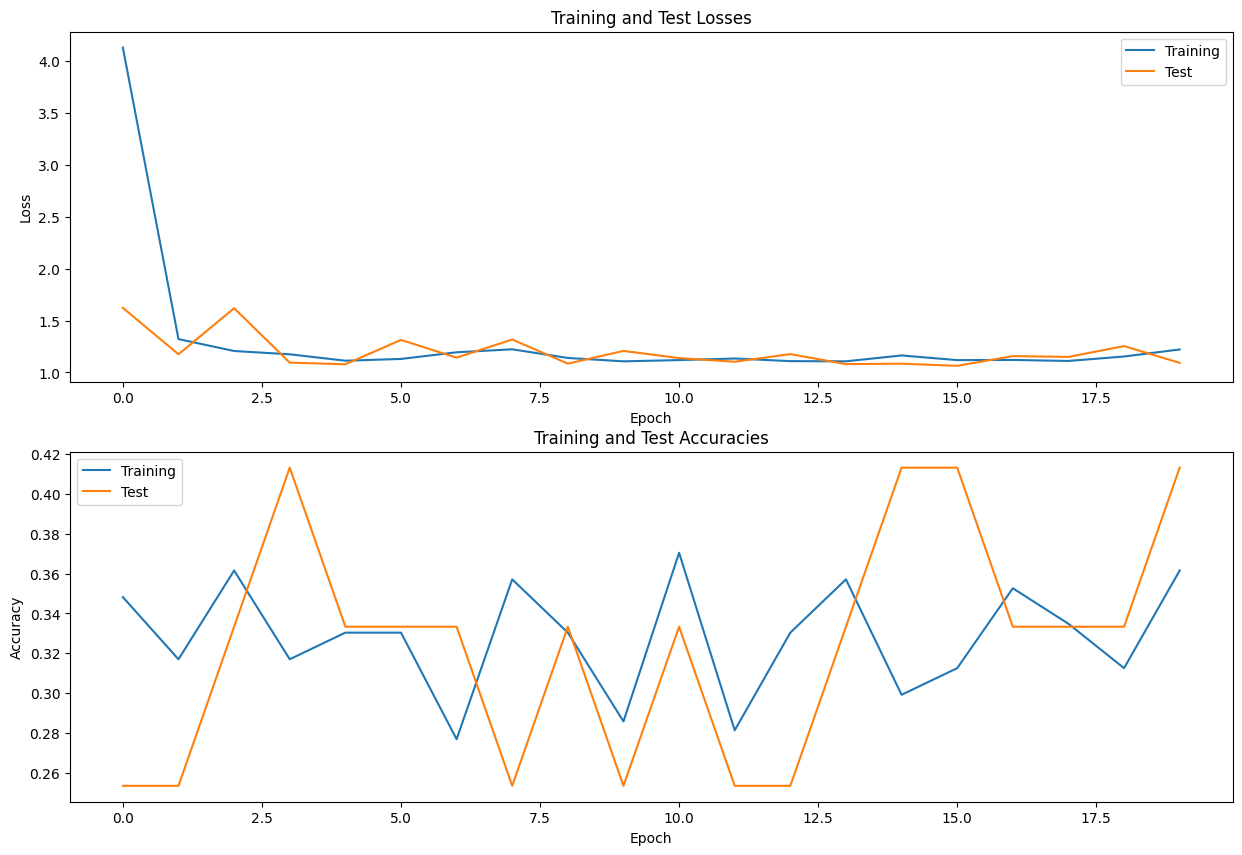

In [28]:
# Plot the training and validation losses and accuracies
fig, axs = plt.subplots(2, 1, figsize=(15, 10))

# Plot the losses
axs[0].plot(losses)
axs[0].set_title("Training and Test Losses")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend(["Training", "Test"])

# Plot the accuracies
axs[1].plot(accuracies)
axs[1].set_title("Training and Test Accuracies")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy")
axs[1].legend(["Training", "Test"])

# Show the plot
plt.show()

In [29]:
# Which classes does the model trained from scratch predict on the test set?
vit.eval()
all_predictions = []
with torch.no_grad():
    for images, labels in test_dataloader:
        all_predictions.append(vit(images.to(device)).argmax(1).cpu())
all_predictions = torch.cat(all_predictions)
for idx, name in enumerate(test_dataset.classes):
    n_true = sum(1 for _, label in test_dataset.samples if label == idx)
    print(f"{name:6s}: predicted for {(all_predictions == idx).sum().item():2d} test images ({n_true} test images are {name})")

pizza : predicted for  0 test images (25 test images are pizza)
steak : predicted for  0 test images (19 test images are steak)
sushi : predicted for 75 test images (31 test images are sushi)


# Part B

## Step 11: Fine-tune a Pretrained ViT

Now we take the same architecture, ViT-Base with 16 x 16 patches (`vit_b_16`), but start from weights that have already been trained on ImageNet-1k (1.3 million images, 1,000 classes). The pretrained model has already learned general visual features, so we only need to adapt it to our three classes:

1. Load the model with the pretrained weights (`ViT_B_16_Weights.IMAGENET1K_V1`; the first time, this downloads about 330 MB).
2. Preprocess the images exactly as they were preprocessed during pretraining. The weights object provides these transforms (`weights.transforms()`): resize to 256, center crop to 224, and normalize with the ImageNet mean and standard deviation. Using different preprocessing would change the statistics of the inputs that the pretrained weights expect.
3. Replace the classification head (a linear layer from 768 features to 1,000 ImageNet classes) with a new linear layer with 3 outputs.
4. Fine-tune *all* the weights for a few epochs with a small learning rate (AdamW, learning rate $10^{-4}$), so that the pretrained features are adjusted gently rather than destroyed.

We reuse the `train` and `evaluate` functions from Part A.

In [30]:
import torchvision

# Free the GPU memory used by the model trained in Part A
del vit, optimizer, lr_scheduler
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Load ViT-Base/16 with ImageNet-1k weights
weights = torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1
pretrained_vit = torchvision.models.vit_b_16(weights=weights)

# The preprocessing that was used when the model was pretrained
pretrained_transform = weights.transforms()
print(pretrained_transform)

# Replace the classification head: 768 features -> 3 classes
print("Original head:", pretrained_vit.heads.head)
pretrained_vit.heads.head = nn.Linear(768, NUM_CLASSES)
print("New head:     ", pretrained_vit.heads.head)
pretrained_vit = pretrained_vit.to(device)

n_trainable = sum(p.numel() for p in pretrained_vit.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_trainable:,}")

# Datasets and dataloaders with the pretrained model's preprocessing
training_dataset_pt = ImageFolder(root=data_dir / "train", transform=pretrained_transform)
test_dataset_pt = ImageFolder(root=data_dir / "test", transform=pretrained_transform)
training_dataloader_pt = DataLoader(training_dataset_pt, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_dataloader_pt = DataLoader(test_dataset_pt, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Original head: Linear(in_features=768, out_features=1000, bias=True)
New head:      Linear(in_features=768, out_features=3, bias=True)
Trainable parameters: 85,800,963


TODO: Before you run the next cell, predict the test accuracy after the first epoch of fine-tuning, and after the last one.

In [31]:
torch.manual_seed(42)
optimizer_pt = torch.optim.AdamW(pretrained_vit.parameters(), lr=1e-4)
N_EPOCHS_FT = 5

for epoch in range(N_EPOCHS_FT):
    train_loss, train_accuracy = train(pretrained_vit, training_dataloader_pt, optimizer_pt, loss_fn, device)
    test_loss, test_accuracy = evaluate(pretrained_vit, test_dataloader_pt, loss_fn, device)
    print(f'Epoch: {epoch+1}, Train Loss: {train_loss:.3f}, Train Acc: {train_accuracy*100:.2f}%, Test Loss: {test_loss:.3f}, Test Acc: {test_accuracy*100:.2f}%')

finetuned_test_accuracy = test_accuracy
print(f"\nPretrained ViT-Base fine-tuned for {N_EPOCHS_FT} epochs: test accuracy = {finetuned_test_accuracy*100:.2f}%")
print(f"ViT-Base trained from scratch for {N_EPOCHS} epochs:    test accuracy = {scratch_test_accuracy*100:.2f}%")

Epoch: 1, Train Loss: 0.504, Train Acc: 79.56%, Test Loss: 1.274, Test Acc: 53.33%


Epoch: 2, Train Loss: 0.269, Train Acc: 90.67%, Test Loss: 0.337, Test Acc: 89.33%


Epoch: 3, Train Loss: 0.066, Train Acc: 97.78%, Test Loss: 0.298, Test Acc: 86.67%


Epoch: 4, Train Loss: 0.026, Train Acc: 98.67%, Test Loss: 0.158, Test Acc: 94.67%


Epoch: 5, Train Loss: 0.023, Train Acc: 99.56%, Test Loss: 0.239, Test Acc: 92.00%

Pretrained ViT-Base fine-tuned for 5 epochs: test accuracy = 92.00%
ViT-Base trained from scratch for 20 epochs:    test accuracy = 41.33%


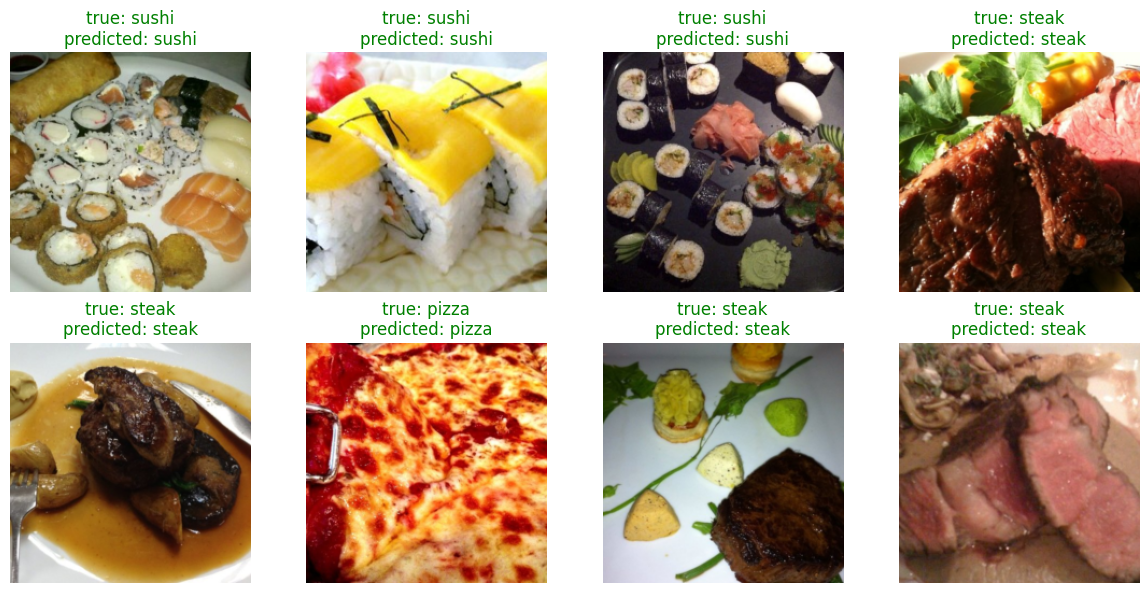

In [32]:
# Look at some test images and the predictions of the fine-tuned model
pretrained_vit.eval()
torch.manual_seed(0)
indices = torch.randperm(len(test_dataset_pt))[:8]  # 8 random test images
images = torch.stack([test_dataset_pt[i][0] for i in indices])
labels = torch.tensor([test_dataset_pt[i][1] for i in indices])
with torch.no_grad():
    predictions = pretrained_vit(images.to(device)).argmax(1).cpu()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, label, prediction in zip(axs.flatten(), images, labels, predictions):
    ax.imshow((image * std + mean).clamp(0, 1).permute(1, 2, 0))  # Undo the normalization for display
    color = "green" if label == prediction else "red"
    ax.set_title(f"true: {test_dataset_pt.classes[label]}\npredicted: {test_dataset_pt.classes[prediction]}", color=color)
    ax.axis(False)
plt.tight_layout()
plt.show()

## Comparing Part A and Part B

| | Part A: ViT-Base trained from scratch | Part B: pretrained ViT-Base, fine-tuned |
|---|---|---|
| Architecture | ViT-Base/16 (our implementation) | ViT-Base/16 (`torchvision`) |
| Trainable parameters | 85,800,963 | 85,800,963 |
| Starting weights | random | pretrained on ImageNet-1k (1.3 million images) |
| Training images for our task | 225 | 225 |
| Epochs | 20 | 5 |
| Test accuracy (our run) | 41.33% | 92.00% |

(Your numbers will vary somewhat with the hardware, library versions, and random seed.)

**Part A.** The model trained from scratch learned nothing useful. Its training loss stays close to $\ln 3 \approx 1.10$, the loss of a model that assigns equal probability to the three classes, and its training accuracy stays around 33%. The test accuracy jumps between exactly three values, 25.33%, 33.33%, and 41.33%, which are the fractions of steak, pizza, and sushi images in the test set (19, 25, and 31 of 75). In other words, after every epoch the model predicts the *same class for every image*. The cell after the plot confirms this for the final model: it predicts sushi for all 75 test images, so the final 41.33% only means that it happened to end on the most frequent test class. That is chance performance, not a sign of learning.

**Part B.** The same architecture, with the same number of parameters and the same 225 training images, reaches 92.00% test accuracy after 5 epochs. (With only 75 test images, one image is worth 1.33 percentage points, so the test accuracy fluctuates noticeably from epoch to epoch and from run to run.) The only difference is the starting point. Pretraining on ImageNet has already taught the model which patches belong together and how to represent edges, textures, and object parts, so fine-tuning only has to learn how to map these features to three new classes.

This is the lesson of the ViT paper in miniature. A transformer has very little inductive bias for images: unlike a convolutional network it does not assume that nearby pixels are related or that features are the same everywhere in the image, so it has to learn all of this from data. With a small dataset it cannot, which is why CNNs, whose architecture builds these assumptions in, usually do better than transformers when trained from scratch on small datasets. With enough pretraining data (the ViT paper used ImageNet-21k and JFT-300M), the lack of built-in assumptions stops being a handicap, and pretrained transformers match or beat the best CNNs. In practice, almost nobody trains a ViT from scratch on a small dataset; they start from pretrained weights, as in Part B.

TODO: Try these experiments:
* In Part A, the learning rate of $10^{-3}$ is high for a transformer trained from scratch (the ViT paper used a learning-rate warmup, very large batches, and strong regularization). Retrain with a learning rate of $10^{-4}$. Does the training accuracy go up? Does the test accuracy?
* In Part B, freeze all the pretrained weights and train only the new head (set `requires_grad = False` for every parameter except those of `pretrained_vit.heads`). How many parameters are trainable now, and how does the test accuracy compare with full fine-tuning?